## Calculating the phonon dispersion and density of states of $GaAs$

Run all cells to calculate the phonon dispersion and phonon density of states of $GaAs$ using quantum-espresso based on the tutorial at https://pranabdas.github.io/espresso/hands-on/phonon

1. Load in modules
2. Plotting updates function
3. Phonon Dispersion
    1. SCF Calculation
    2. Dynamical Matrix Calculation
    3. Real-Space Force Constants
    4. Phonon Frequencies Along the Band Path
    5. Plotting the Phonon Dispersion
4. Phonon Density of States
    1. Phonon DOS Calculation
    2. Plotting the Phonon DOS

**Run time:** section 3.2 is by far the slowest step. The tutorial's run took about a day on a quad-core processor.

**Resuming:** if `ph.x` is interrupted, set `RECOVER = True` in section 1 and run all cells again. This keeps the finished work, skips the SCF step and adds `recover = .true.` to the `ph.x` input.

## 1. Load in modules

In [1]:
# Modules + QE setup for the GaAs phonon workflow:
#   pw.x scf -> ph.x on a q-grid -> q2r.x -> matdyn.x (dispersion, then DOS) -> plot
import math, os, re, shutil, subprocess, time, urllib.request   # run QE executables, fetch pseudopotentials
from pathlib import Path
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

RECOVER = False                                  # True resumes an interrupted ph.x run (see the top of this notebook)

ROOT = Path.cwd()
QE_BIN = ROOT / "qe" / "bin"                     # native Windows build (see build_qe.sh)
PSEUDO_DIR = ROOT / "pseudo"
RUNS = ROOT / "runs"
GAAS_RUN = RUNS / "ph_gaas_live"
GAAS_RUN.mkdir(parents=True, exist_ok=True)
PSEUDO_DIR.mkdir(exist_ok=True)

os.environ["PATH"] = str(QE_BIN) + os.pathsep + os.environ["PATH"]   # bundled MinGW DLLs live here too
# One thread is far faster for small cells on this build (Si SCF: 2.5 s on 1 thread, about 190 s on 12)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ.setdefault("OMP_STACKSIZE", "256M")   # OpenMP threads overflow the default Windows stack
os.environ.setdefault("ESPRESSO_PSEUDO", str(PSEUDO_DIR))

PW = shutil.which("pw.x.exe", path=str(QE_BIN))
PH = shutil.which("ph.x.exe", path=str(QE_BIN))
Q2R = shutil.which("q2r.x.exe", path=str(QE_BIN))
MATDYN = shutil.which("matdyn.x.exe", path=str(QE_BIN))
assert PW and PH and Q2R and MATDYN, f"pw.x / ph.x / q2r.x / matdyn.x not found in {QE_BIN}"

# The tutorial's own copies: the As file isn't on the QE site, and the QE site's Ga file is a newer generation
GA_PSEUDO = "Ga.pbe-dn-kjpaw_psl.1.0.0.UPF"
AS_PSEUDO = "As.nc.z_15.oncvpsp3.dojo.v4-std.upf"
for pseudo in (GA_PSEUDO, AS_PSEUDO):
    if not (PSEUDO_DIR / pseudo).exists():
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/pranabdas/espresso/main/src/pseudos/{pseudo}", PSEUDO_DIR / pseudo)

def run_qe(exe, inp: Path, out: Path | None = None):
    """Run a QE executable on `inp` inside its folder, write stdout to `out` (default: .in -> .out)."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    with open(inp) as fin, open(out, "w") as fout:
        res = subprocess.run([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
    if res.returncode != 0 or "JOB DONE" not in out.read_text(errors="ignore"):
        raise RuntimeError(f"{Path(exe).name} failed on {inp.name} - see {out}")
    return out

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" - {detail}" if detail else ""))

print("pw.x    :", PW)
print("ph.x    :", PH)
print("q2r.x   :", Q2R)
print("matdyn.x:", MATDYN)
for pseudo in (GA_PSEUDO, AS_PSEUDO):
    check("Pseudopotential available", "PP_HEADER" in (PSEUDO_DIR / pseudo).read_text(errors="ignore"), pseudo)

pw.x    : C:\Users\Caesium\Desktop\qe_exp\qe\bin\pw.x.exe
ph.x    : C:\Users\Caesium\Desktop\qe_exp\qe\bin\ph.x.exe
q2r.x   : C:\Users\Caesium\Desktop\qe_exp\qe\bin\q2r.x.exe
matdyn.x: C:\Users\Caesium\Desktop\qe_exp\qe\bin\matdyn.x.exe
[PASS] Pseudopotential available - Ga.pbe-dn-kjpaw_psl.1.0.0.UPF
[PASS] Pseudopotential available - As.nc.z_15.oncvpsp3.dojo.v4-std.upf


## 2. Plotting updates function

`run_calc` writes an input file, runs `pw.x` or `ph.x`, and redraws a plot while it runs so you can see how close the calculation is to finishing. It then checks the result and stops the notebook if the run failed. Stopping the cell also stops the program.

- **SCF:** accuracy per iteration against `conv_thr`.
- **Phonons:** irreducible representations finished out of the total, and the current representation's `|ddv_scf|^2` against `tr2_ph`.

The time left for `ph.x` is a rough estimate: it assumes the remaining representations take as long as the finished ones, but lower-symmetry q-points take longer. A resumed `ph.x` run doesn't print the totals, so its progress bar stays empty and the plots only count what finishes after resuming.

In [2]:
# Live monitor: QE writes to its .out file as it runs, so we re-read that file and redraw
# one figure in place. Each calculation type gets its own view:
#   scf -> accuracy against conv_thr, per iteration
#   ph  -> representations finished, and |ddv_scf|^2 against tr2_ph
BLUE = "#2a78d6"
INK, MUTED, GRID, TRACK, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#f0efec", "#fcfcfb"
NUMBER = r"([0-9.]+(?:[Ee][+-]?[0-9]+)?)"

def read_setting(settings, name, default):
    """Read a number from a QE input. \b stops conv_thr also matching etot_conv_thr."""
    found = re.search(rf"\b{name}\s*=\s*([0-9.eEdD+-]+)", settings)
    return float(found.group(1).lower().replace("d", "e")) if found else default

def read_scf_progress(text):
    """Pull the convergence numbers out of a pw.x output, finished or not."""
    text = text[:text.rfind("\n") + 1]                 # ignore a half-written last line
    return {
        "iteration": len(re.findall(r"iteration #\s*\d+", text)),
        "accuracy": [max(float(a), 1e-30) for a in re.findall(rf"estimated scf accuracy\s+<\s+{NUMBER}", text)],
        "energy": [float(e) for e in re.findall(r"total energy\s+=\s+(-?[0-9.]+) Ry", text)],
        "clock": [float(t) for t in re.findall(r"total cpu time spent up to now is\s+([0-9.]+)", text)],
        "done": "JOB DONE" in text,
    }

def read_ph_progress(text):
    """Pull the progress numbers out of a ph.x output, finished or not."""
    text = text[:text.rfind("\n") + 1]
    table = text.split("Number and degeneracy of irreps per q-point")[-1] if "irreps per q-point" in text else ""
    irreps = [int(n) for n in re.findall(r"^\s*\d+(?:\s+-?\d+\.\d+){3}\s+(\d+)\s*$", table, re.M)]
    clock, finished = 0.0, []
    for found in re.finditer(r"total cpu time :\s+([0-9.]+)|(Convergence has been achieved)", text):
        if found.group(1):
            clock = float(found.group(1))
        else:
            finished.append(clock)
    current = text[text.rfind("Representation #"):] if "Representation #" in text else ""
    return {
        "total": sum(irreps),
        "q_total": len(irreps),
        "q_now": len(re.findall(r"Calculation of q =", text)),
        "finished": finished,
        "clock": clock,
        "ddv": [max(float(v), 1e-30) for v in re.findall(rf"\|ddv_scf\|\^2 =\s+{NUMBER}", current)],
        "done": "JOB DONE" in text,
    }

def scf_estimate(p, conv_thr):
    """Return (fraction of the way to conv_thr on a log scale, seconds left or None)."""
    acc = p["accuracy"]
    if p["done"] or (acc and acc[-1] < conv_thr):
        return 1.0, 0.0
    if not acc:
        return 0.0, None
    fraction = math.log(acc[0] / acc[-1]) / math.log(acc[0] / conv_thr)
    fraction = min(max(fraction, 0.0), 0.99)
    if len(acc) < 2 or len(p["clock"]) < 3:
        return fraction, None
    logs = np.log10(acc[-3:])
    slope = np.polyfit(range(len(logs)), logs, 1)[0]
    if slope >= 0:                                     # not improving, so no honest estimate
        return fraction, None
    steps_left = math.ceil((math.log10(conv_thr) - logs[-1]) / slope)
    return fraction, steps_left * float(np.mean(np.diff(p["clock"])[-3:]))

def ph_estimate(p):
    """Return (fraction of representations finished, seconds left or None)."""
    done, total = len(p["finished"]), p["total"]
    if p["done"]:
        return 1.0, 0.0
    if not total:
        return 0.0, None
    if not p["finished"]:
        return done / total, None
    return min(done / total, 0.99), max(total - done, 0) * p["finished"][-1] / len(p["finished"])

def as_time(seconds):
    if seconds < 90:
        return f"{seconds:.0f} s"
    return f"{seconds / 60:.1f} min" if seconds < 5400 else f"{seconds / 3600:.1f} h"

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

def target_line(ax, y, label):
    ax.axhline(y, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
    ax.annotate(label, (1, y), xycoords=("axes fraction", "data"), xytext=(0, 4),
                textcoords="offset points", ha="right", fontsize=8, color=MUTED)

def count_axis(ax, count):
    ax.set_xlim(0.5, max(count + 1.5, 6))
    ax.xaxis.get_major_locator().set_params(integer=True)

def draw_scf(left, right, p, conv_thr):
    acc = p["accuracy"]
    style(left, "SCF accuracy", "Iteration", "Estimated accuracy (Ry)")
    left.set_yscale("log")
    left.set_ylim(conv_thr / 5, 1)
    target_line(left, conv_thr, f"target {conv_thr:.0e} Ry")
    if acc:
        left.plot(range(1, len(acc) + 1), acc, color=BLUE, linewidth=2, marker="o", markersize=5)
        left.set_ylim(min(min(acc), conv_thr) / 5, max(acc) * 5)
    count_axis(left, len(acc))

    style(right, "Energy change per iteration", "Iteration", "|ΔE| (Ry)")
    right.set_yscale("log")
    right.set_ylim(1e-9, 1)
    change = np.abs(np.diff(p["energy"]))
    if change.size:
        change = np.maximum(change, 1e-12)
        right.plot(range(2, change.size + 2), change, color=BLUE, linewidth=2, marker="o", markersize=5)
        right.set_ylim(change.min() / 5, change.max() * 5)
    count_axis(right, len(acc))

def draw_ph(left, right, p, tr2_ph):
    finished, total = p["finished"], p["total"]
    style(left, "Representations finished", "CPU time (s)", "Representations")
    if total:
        left.axhline(total, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
        left.annotate(f"total {total}", (0, total), xycoords=("axes fraction", "data"),
                      xytext=(4, -11), textcoords="offset points", fontsize=8, color=MUTED)
        left.set_ylim(0, total * 1.08)
    if finished:
        left.plot(finished, range(1, len(finished) + 1), color=BLUE, linewidth=2)

    ddv = p["ddv"]
    style(right, "Current representation", "Iteration", "|ddv_scf|²")
    right.set_yscale("log")
    right.set_ylim(tr2_ph / 5, 1)
    target_line(right, tr2_ph, f"target {tr2_ph:.0e}")
    if ddv:
        right.plot(range(1, len(ddv) + 1), ddv, color=BLUE, linewidth=2, marker="o", markersize=5)
        right.set_ylim(min(min(ddv), tr2_ph) / 5, max(ddv) * 5)
    count_axis(right, len(ddv))

def draw(fig, text, calculation, target, elapsed, finished, failed):
    fig.clf()
    grid = fig.add_gridspec(2, 2, height_ratios=[0.05, 1], hspace=0.42, wspace=0.26,
                            left=0.08, right=0.98, top=0.84, bottom=0.14)
    bar = fig.add_subplot(grid[0, :])
    left, right = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

    if calculation == "scf":
        p = read_scf_progress(text)
        fraction, seconds = scf_estimate(p, target)
        draw_scf(left, right, p, target)
        detail = f"iteration {p['iteration']}"
        if p["accuracy"]:
            detail += f"  ·  accuracy {p['accuracy'][-1]:.1e} Ry"
    else:
        p = read_ph_progress(text)
        fraction, seconds = ph_estimate(p)
        draw_ph(left, right, p, target)
        detail = f"q-point {p['q_now']} of {p['q_total']}  ·  {len(p['finished'])} of {p['total']} representations"
        if not p["total"]:                             # a resumed run doesn't print the totals
            detail = f"resumed run  ·  {len(p['finished'])} representations finished so far"
    running = f"{fraction:.0%}  ·  " + (f"about {as_time(seconds)} left" if seconds is not None else "estimating time left")

    if failed:
        state = f"Stopped before finishing after {as_time(elapsed)}"
    elif finished:
        state = f"Finished in {as_time(elapsed)}"
        fraction = 1.0
    else:
        state = running
    fig.text(0.08, 0.93, f"{calculation.upper()}: {state}", fontsize=12, color=INK, weight="bold")
    fig.text(0.98, 0.93, detail, fontsize=9, color=MUTED, ha="right")

    bar.barh(0, 1, color=TRACK, height=1)
    bar.barh(0, fraction, color=BLUE, height=1)
    bar.set_xlim(0, 1)
    bar.axis("off")

def run_live(exe, inp, calculation, target, refresh):
    """Run `exe` on `inp` and redraw a progress plot while it runs. Returns the exit code."""
    inp = Path(inp)
    out = inp.with_suffix(".out")

    fig = plt.figure(figsize=(10, 4.2), dpi=110, facecolor=SURFACE)
    plt.close(fig)                                     # stops a second copy appearing at the end
    handle = display(fig, display_id=True)

    started = time.time()
    def redraw(finished=False, failed=False):
        text = out.read_text(errors="ignore") if out.exists() else ""
        draw(fig, text, calculation, target, time.time() - started, finished, failed)
        handle.update(fig)

    with open(inp) as fin, open(out, "w") as fout:
        proc = subprocess.Popen([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
        try:
            while proc.poll() is None:
                redraw()
                time.sleep(refresh)
        except BaseException:                          # e.g. the stop button: don't leave the program running
            proc.kill()
            proc.wait()
            redraw(failed=True)
            raise
    ok = proc.returncode == 0 and "JOB DONE" in out.read_text(errors="ignore")
    redraw(finished=ok, failed=not ok)
    return proc.returncode

def run_calc(exe, name, text, run_dir, calculation):
    """Write the input file `name` in `run_dir`, run it with the live plot, check it, and return its output."""
    inp = Path(run_dir) / name
    inp.write_text(text)
    target, refresh = (read_setting(text, "conv_thr", 1e-6), 1.0) if calculation == "scf" else (read_setting(text, "tr2_ph", 1e-12), 5.0)

    t0 = time.time()
    returncode = run_live(exe, inp, calculation, target, refresh)
    elapsed = time.time() - t0
    output = inp.with_suffix(".out").read_text(errors="ignore")

    if calculation == "scf":
        label, finished = "SCF converged", "convergence has been achieved" in output
    else:
        # GaAs.dyn0 lists the q-points: its second line is how many, and each one gets a GaAs.dynN file
        grid = Path(run_dir) / "GaAs.dyn0"
        q_total = int(grid.read_text().split()[3]) if grid.exists() else 0
        missing = [n for n in range(1, q_total + 1) if not (Path(run_dir) / f"GaAs.dyn{n}").exists()]
        label, finished = f"Dynamical matrices written for all {q_total} q-points", q_total > 0 and not missing

    results = [returncode == 0, "JOB DONE" in output, finished]
    check(f"{Path(exe).stem} exit code 0", results[0], f"code {returncode}")
    check("JOB DONE", results[1], as_time(elapsed))
    check(label, results[2])
    if not all(results):                               # stop here so later steps don't run on bad data
        message = re.search(r"%{20,}\n(.*?)\n\s*%{20,}", output, re.S)
        raise RuntimeError(f"{name} failed: {' '.join(message.group(1).split()) if message else 'see ' + inp.with_suffix('.out').name}")
    return output

## 3. Phonon Dispersion

### 3.1 SCF Calculation

Uses `pw.x` to find the ground-state charge density and wavefunctions of zincblende GaAs, which `ph.x` starts from. The cutoffs are higher than usual because phonon calculations need the extra accuracy.

In [3]:
GAAS_SCF_INPUT = f'''&control
  calculation = 'scf'
  prefix = 'GaAs'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  outdir = './tmp/'
  verbosity = 'high'
  wf_collect = .true.
/
&system
  ibrav = 2
  celldm(1) = 10.861462
  nat = 2
  ntyp = 2
  ecutwfc = 80
  ecutrho = 640
/
&electrons
  mixing_mode = 'plain'
  mixing_beta = 0.7
  conv_thr = 1.0e-8
/
ATOMIC_SPECIES
  Ga 69.723    {GA_PSEUDO}
  As 74.921595 {AS_PSEUDO}
ATOMIC_POSITIONS (alat)
  Ga 0.00 0.00 0.00
  As 0.25 0.25 0.25
K_POINTS {{automatic}}
  8 8 8 0 0 0
'''

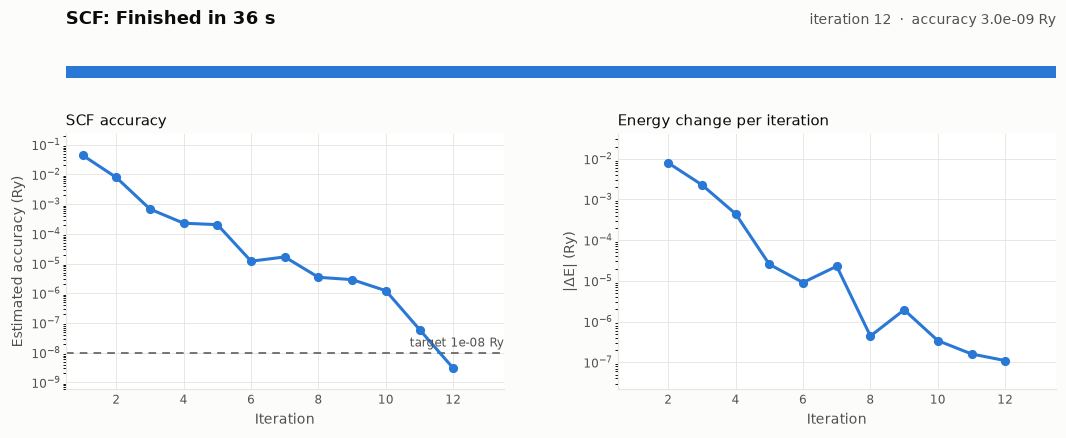

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 37 s
[PASS] SCF converged


In [4]:
# Equivalent of:  pw.x < pw.scf.GaAs.in > pw.scf.GaAs.out, with a live convergence plot
if RECOVER:
    print("RECOVER is on: keeping the existing SCF result, because ph.x restarts from it")
    GAAS_SCF_OUT = (GAAS_RUN / "pw.scf.GaAs.out").read_text(errors="ignore")
else:
    GAAS_SCF_OUT = run_calc(PW, "pw.scf.GaAs.in", GAAS_SCF_INPUT, GAAS_RUN, "scf")

### 3.2 Dynamical Matrix Calculation

Uses `ph.x` (density functional perturbation theory) to calculate the dynamical matrix at each point of a uniform 6×6×6 q-grid. At Γ it also calculates the dielectric tensor and Born effective charges, which give the LO-TO splitting of this polar crystal.

With the tutorial's settings the dielectric constant comes out at about 554, far above the experimental value of about 11, so expect very little LO-TO splitting in the plot.

This is the slow step. To stop it cleanly, create an empty file called `GaAs.EXIT` in `runs/ph_gaas_live`. To resume after any interruption, see the top of this notebook.

In [5]:
GAAS_PH_INPUT = f'''&INPUTPH
  outdir = './tmp/'
  prefix = 'GaAs'
  tr2_ph = 1d-14
  ldisp = .true.
  {'recover = .true.' if RECOVER else '! recover = .true.'}
  nq1 = 6
  nq2 = 6
  nq3 = 6
  fildyn = 'GaAs.dyn'
/
'''

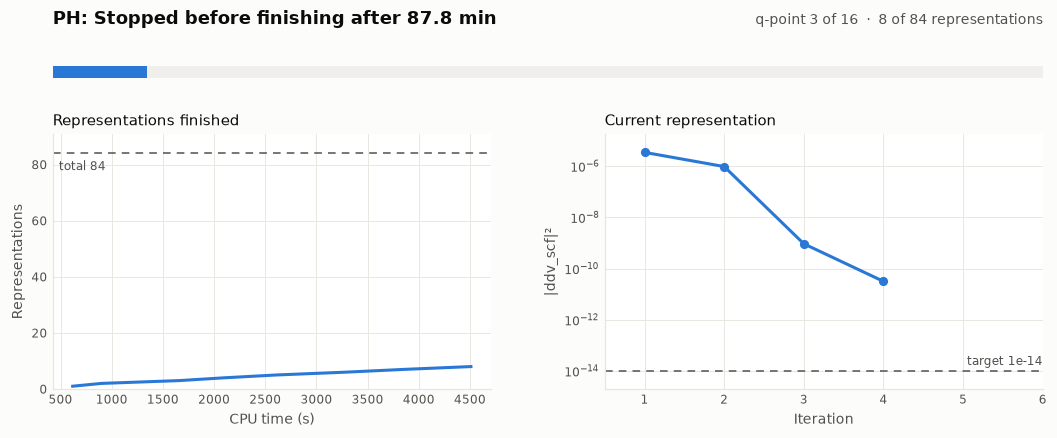

KeyboardInterrupt: 

In [6]:
# Equivalent of:  ph.x < ph.GaAs.in > ph.GaAs.out, with a live progress plot
GAAS_PH_OUT = run_calc(PH, "ph.GaAs.in", GAAS_PH_INPUT, GAAS_RUN, "ph")

### 3.3 Real-Space Force Constants

Uses `q2r.x` to inverse Fourier transform the dynamical matrices on the q-grid into interatomic force constants in real space.

In [ ]:
GAAS_Q2R = '''&INPUT
  fildyn = 'GaAs.dyn'
  zasr = 'crystal'
  flfrc = 'GaAs.fc'
/
'''
(GAAS_RUN / "q2r.GaAs.in").write_text(GAAS_Q2R)

# Equivalent of:  q2r.x < q2r.GaAs.in > q2r.GaAs.out
run_qe(Q2R, GAAS_RUN / "q2r.GaAs.in")
check("q2r.x wrote force constants", (GAAS_RUN / "GaAs.fc").exists())

### 3.4 Phonon Frequencies Along the Band Path

Uses `matdyn.x` to Fourier transform the force constants back to a dynamical matrix at any q, and calculates the frequencies along the path L → Γ → X → K → Γ.

In [ ]:
GAAS_MATDYN = '''&INPUT
  asr = 'crystal'
  flfrc = 'GaAs.fc'
  flfrq = 'GaAs.freq'
  flvec = 'GaAs.modes'
  q_in_band_form = .true.
  q_in_cryst_coord = .true.
/
5
0.500 0.500 0.500   20 ! L
0.000 0.000 0.000   20 ! G
0.500 0.000 0.500   20 ! X
0.375 0.375 0.750   20 ! K
0.000 0.000 0.000    1 ! G
'''
(GAAS_RUN / "matdyn.GaAs.in").write_text(GAAS_MATDYN)

# Equivalent of:  matdyn.x < matdyn.GaAs.in > matdyn.GaAs.out
run_qe(MATDYN, GAAS_RUN / "matdyn.GaAs.in")
check("matdyn.x wrote frequencies", (GAAS_RUN / "GaAs.freq.gp").exists())

### 3.5 Plotting the Phonon Dispersion

Plots the six phonon branches along the path. The axis starts at zero as in the tutorial, so the check below reports the lowest frequency, because an imaginary mode (shown as negative) would otherwise be hidden.

In [ ]:
data = np.loadtxt(GAAS_RUN / "GaAs.freq.gp")
check("No imaginary frequencies", data[:, 1:].min() > -5, f"lowest {data[:, 1:].min():.2f} cm-1")

fig, ax = plt.subplots(figsize=(8, 6), dpi=150, facecolor="white")
for band in range(data.shape[1] - 1):
    ax.plot(data[:, 0], data[:, band + 1], linewidth=1, alpha=0.5, color="k")

# High symmetry q-points (check matdyn.GaAs.in)
ticks = [data[0, 0], data[20, 0], data[40, 0], data[60, 0], data[-1, 0]]
for tick in ticks[:-1]:
    ax.axvline(tick, linewidth=0.5, color="k", alpha=0.5)
ax.set_xticks(ticks, labels=["L", r"$\Gamma$", "X", "U,K", r"$\Gamma$"])
ax.set_ylabel("Frequency (cm$^{-1}$)")
ax.set_xlim(data[0, 0], data[-1, 0])
ax.set_ylim(0, )
ax.set_title("GaAs phonon dispersion")
plt.show()

## 4. Phonon Density of States

### 4.1 Phonon DOS Calculation

Reruns `matdyn.x` with `dos = .true.` to calculate the frequencies on a dense 25×25×25 q-grid and count the modes at each frequency, in total and projected onto the Ga and As atoms.

In [ ]:
GAAS_MATDYN_DOS = '''&INPUT
  asr   = 'crystal'
  flfrc = 'GaAs.fc'
  flfrq = 'GaAs.dos.freq'
  flvec = 'GaAs.dos.modes'
  dos   = .true.
  fldos = 'GaAs.dos'
  nk1   = 25
  nk2   = 25
  nk3   = 25
/
'''
(GAAS_RUN / "matdyn.dos.GaAs.in").write_text(GAAS_MATDYN_DOS)

# Equivalent of:  matdyn.x < matdyn.dos.GaAs.in > matdyn.dos.GaAs.out
run_qe(MATDYN, GAAS_RUN / "matdyn.dos.GaAs.in")
check("matdyn.x wrote the DOS", (GAAS_RUN / "GaAs.dos").exists())

### 4.2 Plotting the Phonon DOS

Plots the total phonon DOS with its Ga and As projections.

In [ ]:
freq, dos, pdos_Ga, pdos_As = np.loadtxt(GAAS_RUN / "GaAs.dos", unpack=True)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150, facecolor="white")
ax.plot(freq, dos, c="k", lw=0.5, label="Total")
ax.plot(freq, pdos_Ga, c="b", lw=0.5, label="Ga")
ax.plot(freq, pdos_As, c="r", lw=0.5, label="As")
ax.set_xlabel(r"$\Omega~(cm^{-1}$)")
ax.set_ylabel("Phonon DOS (state/cm$^{-1}/u.c.$)")
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(freq[0], freq[-1])
ax.set_title("GaAs phonon density of states")
plt.show()